# Part 3 - SLAM Global Localization: Accumulation of Uncertainty Through Drift

This notebook demonstrates odometry drift and uncertainty accumulation in VIO-based SLAM systems using ARP_utility_code sensors.

In [1]:
# Imports

import sys
sys.path.insert(0, '../src')

import part3_functions
from config import TrajectoryConfig, VIOConfig

import numpy as np


from config import TrajectoryConfig, VIOConfig
from trajectory import generate_trajectory, sgal3_to_se2_poses
from vio_sensor import simulate_vio_odometry
from relative_pose import compute_relative_poses

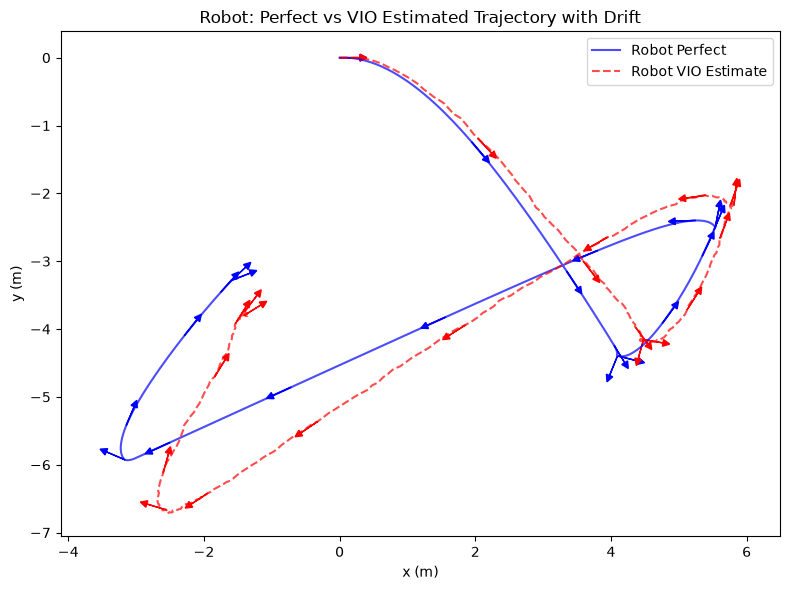

In [2]:
# Parameters for robot 1 trajectory + VIO simulation

traj_config = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)
vio_config = VIOConfig(sig_v=0.1, sig_w=0.05)

poses_robot1_perfect, poses_robot1_noisy = part3_functions.plot_single_robot_vio(traj_config, vio_config)

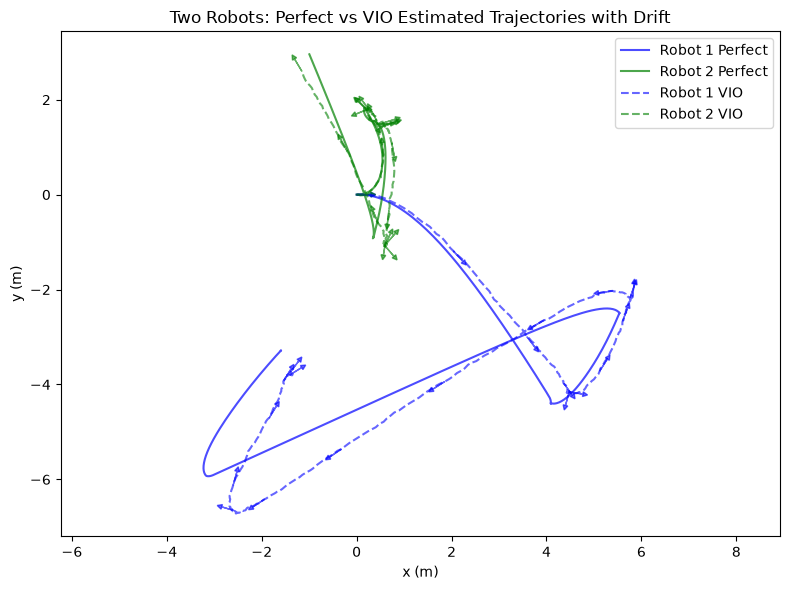

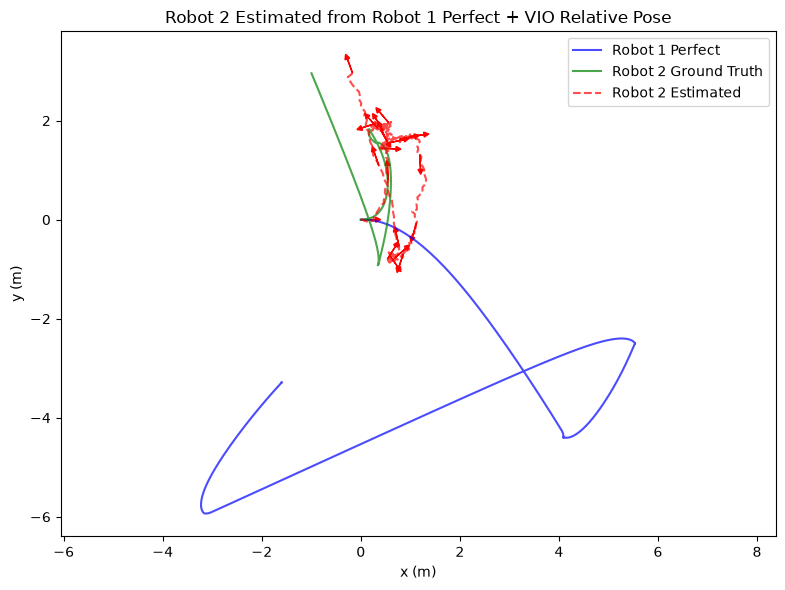

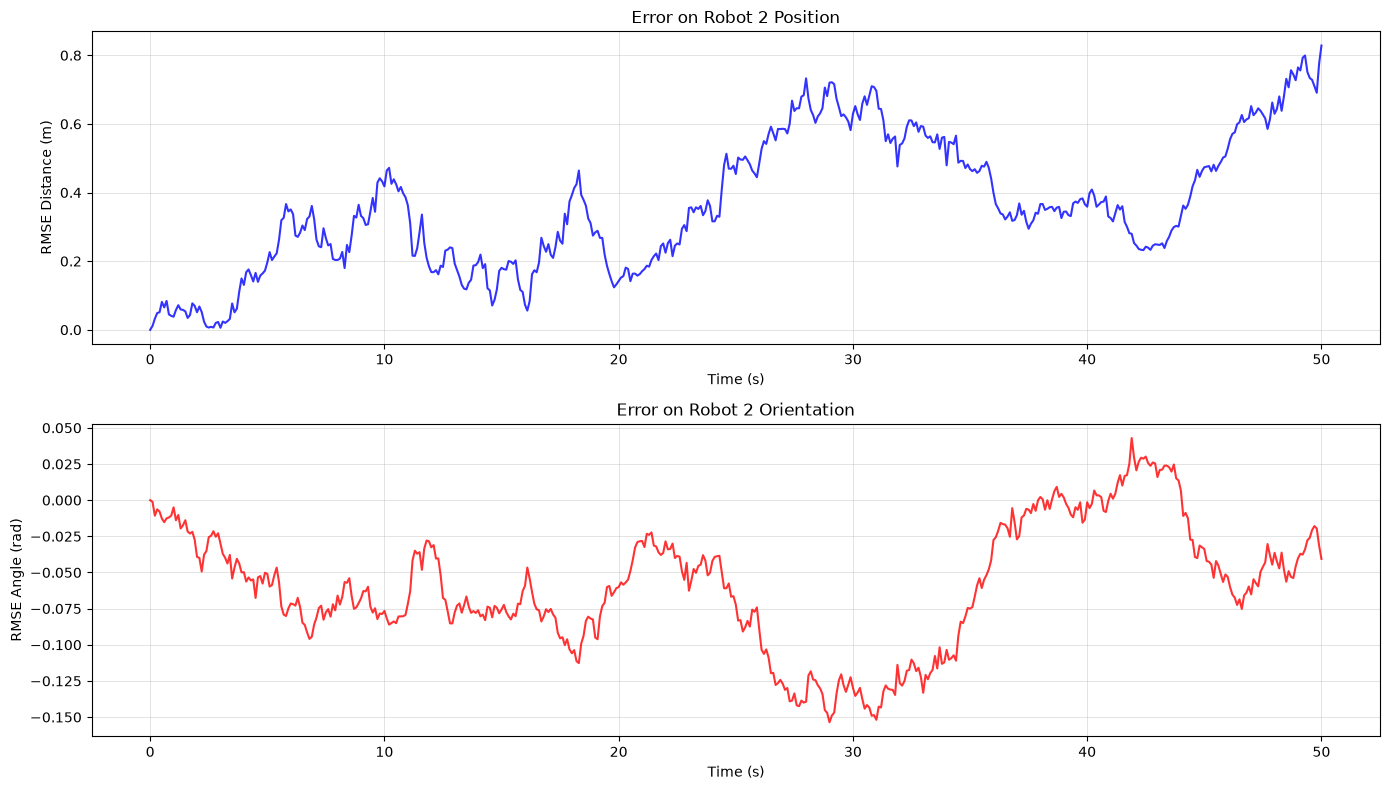

(array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 9.76451336e-02,  1.45418080e-03, -7.85398163e-02],
        [ 1.93114295e-01, -6.80918175e-03, -1.53438868e-01],
        ...,
        [-1.59223379e+00, -3.28259451e+00,  5.30030793e-01],
        [-1.59341129e+00, -3.28324907e+00,  4.51490976e-01],
        [-1.59399061e+00, -3.28354733e+00,  3.72951160e-01]],
       shape=(501, 3)),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.00655426e-01, -1.59400358e-03, -7.85674557e-02],
        [ 1.94592745e-01,  1.57504950e-03, -1.47498309e-01],
        ...,
        [-1.38524446e+00, -3.79119440e+00,  7.00830491e-01],
        [-1.41030981e+00, -3.79648800e+00,  6.29189868e-01],
        [-1.41288023e+00, -3.80267536e+00,  5.57083038e-01]],
       shape=(501, 3)),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.39560597e-02,  1.54498360e-03,  7.85398163e-02],
        [ 8.56230567e-02,  4.94896137e-03,  1.57079633e-01],
        .

In [3]:
# Parameters for robot 2 trajectory + VIO simulation

traj_config_robot1 = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)
vio_config_robot1 = VIOConfig(sig_v=0.1, sig_w=0.05)

traj_config_robot2 = TrajectoryConfig(
    duration=50.0,
    timestep=0.1,
    seed=123,
    start_x=2.0,
    start_y=2.0,
    start_theta=np.deg2rad(45)
)
vio_config_robot2 = VIOConfig(sig_v=0.1, sig_w=0.05)

part3_functions.plot_two_robots_vio(
    traj_config_robot1,
    vio_config_robot1,
    traj_config_robot2,
    vio_config_robot2
)

# Cell 5: Conclusion on drift

## Summary of Key Findings

### 1. VIO Odometry Drift
- VIO sensors provide pose estimates that accumulate uncertainty over time
- Gaussian noise in velocity and angular velocity measurements propagates through integration
- Error grows monotonically as the robot moves - this is known as *drift*
- The drift appears as a progressive deviation from the ground truth trajectory

### 2. Uncertainty Accumulation Mechanism
- At each time step, VIO integrates noisy velocity measurements: `p_{k+1} = p_k + v_k * dt`
- Velocity noise is added at each integration step, causing errors to accumulate
- Angular velocity noise causes orientation drift, which in turn rotates the velocity estimate
- The cumulative effect leads to increasingly large pose estimation errors over time

### 3. Comparison with Part 1 & 2
- In Part 1 (VICON), we had perfect global measurements - no drift
- In Part 2 (UWB), we had periodic global corrections based on range measurements
- Here in Part 3, VIO provides *only* local measurements, so errors accumulate without correction
- SLAM systems that use only odometry will exhibit this same drift behavior unless they incorporates loop closures or external constraints

### 4. Key Takeaway
VIO and similar inertial sensors provide high-frequency pose estimates but suffer from drift due to integration of noisy measurements. To obtain accurate long-term localization, these must be combined with absolute position measurements (e.g., GPS, visual landmarks, UWB anchors) to correct the accumulated error.